# The Gerchberg-Saxton loop on nine traps

**Question:** What does each half of a Gerchberg-Saxton iteration do to the traps, and what does the loop converge to?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 01 and notebook 01 of topic 02
- **Reading time:** about 40 minutes

## Objectives

An iterative method makes a hologram by going back and forth between two planes: in the plane of the traps it fixes what is wanted, in the plane of the SLM it fixes what the device can do. This notebook opens one iteration of Gerchberg-Saxton into its two halves and runs each by hand on the smallest case of the product, nine equal traps on a square. You will see the forward half measure the traps, the constraint replace their amplitudes and keep their phases, and the backward half send the result to the SLM, where only the phase can be kept. You will then check that the engine's own iteration is exactly those steps, run thirty iterations, and read what the loop converges to and what it does not.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m02_random_superposition, m04_gs

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def amp_spread(v):
    """Relative standard deviation of the trap amplitudes, in percent."""
    return 100.0 * np.std(np.abs(v)) / np.mean(np.abs(v))

numpy 2.4.6
matplotlib 3.11.2


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic case written by the product, no third-party dataset, covered by the repository licence.
- File read: `data/examples/cases.json`, case C01, nine traps 3.98 um apart on the 256 by 256 pixel SLM, with the case seed.

In [2]:
# case C01: nine equal traps on a 3 x 3 square, 8 bins apart; the target amplitude of trap m is sqrt(w_m)
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C01_square_grid"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
seed = rec["seed"]
amp = np.sqrt(traps.weight)
print(f"{len(traps)} traps, target amplitudes {amp}")

9 traps, target amplitudes [1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Method

Let $V_m = \frac{1}{N^2}\sum_j A_j e^{i(\phi_j - \Delta_j^m)}$ be the field at trap $m$ for the hologram $\phi$, the sum running over the $N^2$ pixels of an $N$ by $N$ SLM as in topic 01, and $a_m = \sqrt{w_m}$ the target amplitude. One iteration of Gerchberg-Saxton is
$$\phi_j^{k} = \arg \sum_m a_m \frac{V_m^{k-1}}{|V_m^{k-1}|}\, e^{+i\Delta_j^m}$$
(Di Leonardo et al. 2007, Table 1, https://doi.org/10.1364/OE.15.001913). It reads in three moves. The forward half computes $V_m$ from the current hologram. The constraint keeps the phase of each $V_m$ and sets its amplitude to $a_m$. The backward half sums the $M$ gratings with those complex coefficients to get a complex field on the SLM, and keeps only its phase, since the device modulates phase alone. The start is the random-phase superposition of the previous topic. The cells below run the three moves one by one, with the numbers of each shown.

The first cell builds the start and runs the forward half on it: the nine fields $V_m$ of the random-superposition hologram. It prints the nine trap powers, the three array numbers of topic 01, and the relative spread of the amplitudes $|V_m|$, which is the quantity the constraint is about to remove.

In [3]:
# the start: random-phase superposition (M02), then the first half step, the forward one
phi0 = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(seed)).phi
v0 = forward.point_trap_fields(phi0, setup, traps)
i0 = metrics.trap_intensities(v0)
print("powers of the nine traps at the start:", np.round(i0, 4))
print(f"e = {metrics.efficiency(i0):.4f}, u = {metrics.uniformity(i0):.4f}, sigma = {metrics.rel_std(i0):.2f} %")
print(f"amplitude spread: {amp_spread(v0):.2f} %")

powers of the nine traps at the start: [0.0648 0.1363 0.0827 0.0767 0.0738 0.0782 0.0667 0.0681 0.097 ]
e = 0.7442, u = 0.6444, sigma = 25.51 %
amplitude spread: 11.84 %


The constraint is arithmetic. For each trap the coefficient is $c_m = a_m V_m/|V_m|$: the same phase as the measured field and the amplitude that was asked for. The cell prints the amplitudes of the coefficients, the largest phase change the constraint made (it should be zero to rounding) and the amplitude spread afterwards, which is zero by construction.

In [4]:
# the constraint: keep the phase of every trap field, replace its amplitude by the target amplitude
coeffs = amp * v0 / np.abs(v0)
print("amplitudes after the constraint:", np.round(np.abs(coeffs), 4))
print(f"largest phase change of the constraint: {np.abs(np.angle(coeffs / v0)).max():.1e} rad")
print(f"amplitude spread: {amp_spread(coeffs):.2f} %")

amplitudes after the constraint: [1. 1. 1. 1. 1. 1. 1. 1. 1.]
largest phase change of the constraint: 1.4e-17 rad
amplitude spread: 0.00 %


The backward half takes the coefficients to the SLM. The adjoint of the forward half, `point_trap_backproject`, sums $\sum_m c_m e^{+i\Delta_j^m}$ over the traps and gives a complex field on the pixels. Its amplitude is not constant, and the SLM cannot show an amplitude, so the cell keeps only the angle, then runs the forward half again on that phase-only hologram and prints the array numbers and the amplitude spread.

In [5]:
# the second half step: send the corrected trap fields back to the SLM and keep only the phase
field_slm = forward.point_trap_backproject(coeffs, setup, traps)
phi1 = np.angle(field_slm)
amplitude = np.abs(field_slm)
print("amplitude of the back-projected SLM field:")
print(f"    min {amplitude.min():.3f}, mean {amplitude.mean():.3f}, max {amplitude.max():.3f}")
v1 = forward.point_trap_fields(phi1, setup, traps)
i1 = metrics.trap_intensities(v1)
print(f"e = {metrics.efficiency(i1):.4f}, u = {metrics.uniformity(i1):.4f}, sigma = {metrics.rel_std(i1):.2f} %")
print(f"amplitude spread: {amp_spread(v1):.2f} %")

amplitude of the back-projected SLM field:
    min 0.056, mean 2.795, max 5.561
e = 0.7831, u = 0.6642, sigma = 21.81 %
amplitude spread: 10.22 %


That is the whole iteration. The engine's method M04 should do exactly this when asked for one iteration from the same start with the point-trap form, and the cell compares the two holograms by the largest wrapped phase difference between them.

In [6]:
# the same single iteration by the engine: M04 with a one-iteration budget, the same start and the point form
step = m04_gs.run(setup, target, budget=Budget(1), rng=Rng(seed), init=phi0, form="point")
wrapped = np.angle(np.exp(1j * (step.phi - phi1)))
print(f"largest phase difference, hand-made step and M04: {np.abs(wrapped).max():.1e} rad")

largest phase difference, hand-made step and M04: 0.0e+00 rad


Now the loop. The engine has two forms of the same iteration: the point-trap form that this notebook used by hand, and the FFT form, which reads and writes the zero-padded transform at the trap bins and is the default when traps sit on bins. They are the same linear map, so they must give the same hologram up to the rounding of the case: the case stores trap positions to 0.1 nm, so they lie a little off the centres of their bins. The cell prints that offset and compares the two forms after 1, 8 and 30 iterations, by the largest and the median phase difference over the pixels. The largest difference is a poor summary, because the phase of a pixel where the back-projected field is nearly zero is very sensitive to a tiny change.

In [7]:
# the point-trap form and the FFT form from the same start, after 1, 8 and 30 iterations
bin_m = geometry.focal_bin_m(setup)
offset = np.abs(traps.x_m / bin_m - np.rint(traps.x_m / bin_m)).max()
print(f"largest distance of a trap from the centre of its bin: {offset:.1e} bins")
forms = {}
for form in ("point", "fft"):
    forms[form] = {}
    for k in (1, 8, 30):
        forms[form][k] = m04_gs.run(setup, target, budget=Budget(k), rng=Rng(seed), init=phi0, form=form)
for k in (1, 8, 30):
    gap = np.angle(np.exp(1j * (forms["point"][k].phi - forms["fft"][k].phi)))
    print(f"largest phase difference of the two forms after {k:2d} iterations:")
    print(f"    largest {np.abs(gap).max():.1e}, median {np.median(np.abs(gap)):.1e} rad")
run_point = forms["point"][30]
last = run_point.history[-1]
e, u, sigma = last["efficiency"], last["uniformity"], last["rel_std"]
print(f"M04, 30 iterations: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")

largest distance of a trap from the centre of its bin: 5.0e-05 bins
largest phase difference of the two forms after  1 iterations:
    largest 6.0e-03, median 2.8e-05 rad
largest phase difference of the two forms after  8 iterations:
    largest 4.0e-03, median 3.3e-05 rad
largest phase difference of the two forms after 30 iterations:
    largest 4.0e-03, median 3.4e-05 rad
M04, 30 iterations: e = 0.8193, u = 0.8794, sigma = 7.34 %


Every method returns a history with the efficiency, uniformity and relative spread at each iteration. The cell prints it at six iterations and looks for the iteration of the best uniformity.

In [8]:
# the history that every method returns: one entry per iteration
for k in (1, 2, 5, 10, 20, 30):
    h = run_point.history[k - 1]
    print(f"iteration {k:2d}: e = {h['efficiency']:.4f}, u = {h['uniformity']:.4f}, sigma = {h['rel_std']:.2f} %")
uniformity = [h["uniformity"] for h in run_point.history]
spread = [h["rel_std"] for h in run_point.history]
print(f"uniformity is highest at iteration {int(np.argmax(uniformity)) + 1}: u = {max(uniformity):.4f}")
print(f"the spread is lowest at iteration {int(np.argmin(spread)) + 1}: sigma = {min(spread):.2f} %")

iteration  1: e = 0.7831, u = 0.6642, sigma = 21.81 %
iteration  2: e = 0.8021, u = 0.7701, sigma = 13.90 %
iteration  5: e = 0.8174, u = 0.9029, sigma = 5.75 %
iteration 10: e = 0.8189, u = 0.8910, sigma = 6.50 %
iteration 20: e = 0.8192, u = 0.8817, sigma = 7.19 %
iteration 30: e = 0.8193, u = 0.8794, sigma = 7.34 %
uniformity is highest at iteration 4: u = 0.9041
the spread is lowest at iteration 5: sigma = 5.75 %


The first figure follows the nine traps. Each curve is the power of the traps relative to their mean at the start and after 1, 5 and 30 iterations.

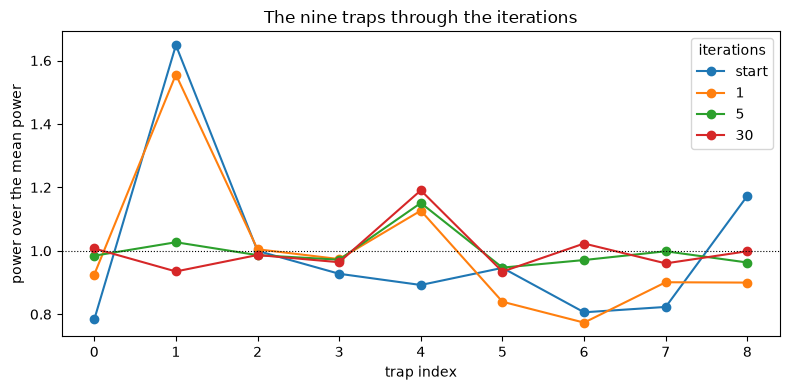

In [9]:
# the power of each of the nine traps at the start and after 1, 5 and 30 iterations
run_one = forms["point"][1]
run_five = m04_gs.run(setup, target, budget=Budget(5), rng=Rng(seed), init=phi0, form="point")
fig, ax = plt.subplots(figsize=(8, 4))
for label, res in (("start", None), ("1", run_one), ("5", run_five), ("30", run_point)):
    i = i0 if res is None else metrics.trap_intensities(res.fields)
    ax.plot(np.arange(9), i / i.mean(), "o-", label=label)
ax.axhline(1.0, color="k", lw=0.8, ls=":")
ax.set_xlabel("trap index")
ax.set_ylabel("power over the mean power")
ax.set_title("The nine traps through the iterations")
ax.legend(title="iterations")
fig.tight_layout()
plt.show()

At the start two traps are far from the rest, trap 1 at about 1.65 of the mean and trap 8 at about 1.2, and trap 6 is at 0.8. After one iteration trap 1 is still at about 1.55, while traps 0, 4, 5 and 8 move by 0.1 to 0.27 of the mean (trap 0 from 0.78 to 0.92, trap 8 from 1.17 to 0.90), and the spread falls from 25.51 to 21.81 percent: one iteration already moves the powers, though not the brightest trap. After five iterations the nine traps lie between about 0.93 and 1.15 of the mean. The thirtieth iteration is not better: the curve is slightly less flat than at iteration five, and trap 4 sits near 1.2. The figure does not say why; the next one does.

The second figure plots the efficiency, the uniformity and the relative spread against the iteration for the thirty iterations.

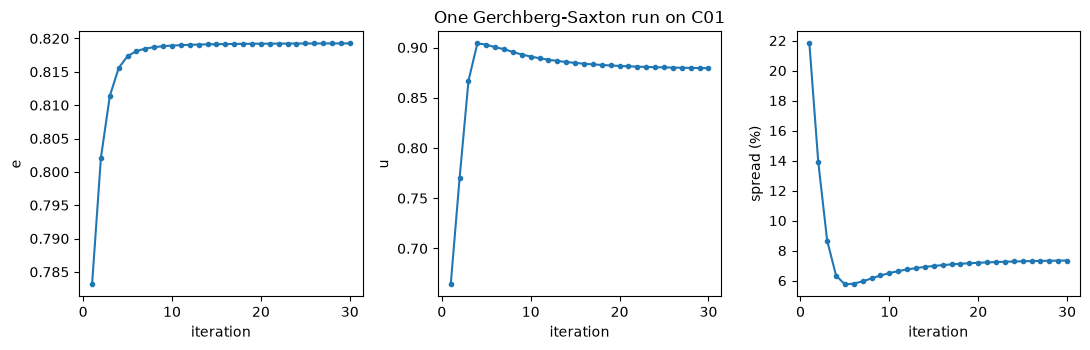

In [10]:
# efficiency, uniformity and relative spread against the iteration
steps = np.arange(1, 31)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, key, label in zip(axes, ("efficiency", "uniformity", "rel_std"), ("e", "u", "spread (%)")):
    ax.plot(steps, [h[key] for h in run_point.history], "o-", ms=3)
    ax.set_xlabel("iteration")
    ax.set_ylabel(label)
axes[1].set_title("One Gerchberg-Saxton run on C01")
fig.tight_layout()
plt.show()

The efficiency rises from 0.7831 to 0.8193 and flattens by iteration 10: the loop converges in the sense that the hologram stops changing the light that reaches the traps. The uniformity does not: it peaks at 0.9041 at iteration 4, falls to 0.8794 at iteration 30, and the spread passes through a minimum of 5.75 percent at iteration 5 and rises to 7.34 percent. This is the standing limitation of plain Gerchberg-Saxton, which has no mechanism that cares about the traps being equal after the constraint has been applied: the constraint sets equal amplitudes at every iteration, but the phase-only projection undoes part of it, and the loop settles at a fixed point of the two operations that is not the equal array. The figure shows the effect but not its cause in any one trap, and a different start would give a different curve.

## Results

**Answer:** The forward half measures each trap's field: at the start the nine powers differ with a spread of 25.51 percent and the amplitudes by 11.84 percent. The constraint keeps their phases and sets all nine amplitudes to 1, so the amplitude spread is 0.00 percent. The backward half sends the coefficients to the SLM and keeps only the phase of a field whose amplitude runs from 0.056 to 5.561; the traps then have a spread of 10.22 percent in amplitude, so the phase-only step gives back part of the error the constraint removed. One such iteration, done by hand, is identical to one iteration of M04 (difference 0.0e+00 rad), and the two forms of the engine agree to a median phase difference of 3.4e-05 rad after 30 iterations. Over 30 iterations the efficiency settles at 0.8193 but the uniformity peaks at 0.9041 at iteration 4 and ends at 0.8794: Gerchberg-Saxton converges to a hologram that is efficient, not uniform.

## Summary

One iteration is a forward transform, an amplitude constraint at the traps and a phase-only projection at the SLM. The constraint is exact; the projection is where the error returns, because a phase-only field cannot carry the amplitudes the constraint asked for. The loop's fixed point is efficient but not uniform for this array. The weighted variants of the next notebook change the coefficient of the constraint step so that traps that came out too dim are asked for more.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.